In [ ]:
import os
from google.colab import drive

In [ ]:
drive.mount('/content/drive')
BASE_PATH = '/content/drive/My Drive/EVAHAN/img_benchmark_Decembre25/'

Mounted at /content/drive


In [ ]:
import random

lstfiles = os.listdir(os.path.join(BASE_PATH, "imgs"))
lstaugm = os.listdir(os.path.join(BASE_PATH, "synthetic"))
lstaugm = random.sample(lstaugm, int(len(lstaugm)*0.1)) # GENERE UN TIRAGE NOUVEAU A CHAQUE FOIS QU'EXECUTE

FILES = lstfiles
AUGMENTED_FILES = lstaugm

MERGED = sorted(FILES + AUGMENTED_FILES)
for idx in range(len(MERGED)):
    if "synthetic" in MERGED[idx]:
        MERGED[idx] = os.path.join(BASE_PATH, "synthetic", MERGED[idx])
    else:
        MERGED[idx] = os.path.join(BASE_PATH, "imgs", MERGED[idx])

In [ ]:
MERGED

['/content/drive/My Drive/EVAHAN/img_benchmark_Decembre25/imgs/1stPaperANTExtractComparaison.png',
 '/content/drive/My Drive/EVAHAN/img_benchmark_Decembre25/synthetic/1stPaperANTExtractComparaison_synthetic_9.jpg',
 '/content/drive/My Drive/EVAHAN/img_benchmark_Decembre25/imgs/Bourbaki.png',
 '/content/drive/My Drive/EVAHAN/img_benchmark_Decembre25/imgs/Bourbaki1.png',
 '/content/drive/My Drive/EVAHAN/img_benchmark_Decembre25/synthetic/Bourbaki1_synthetic_5.jpg',
 '/content/drive/My Drive/EVAHAN/img_benchmark_Decembre25/imgs/Bourbaki2.png',
 '/content/drive/My Drive/EVAHAN/img_benchmark_Decembre25/synthetic/Bourbaki2_synthetic_15.jpg',
 '/content/drive/My Drive/EVAHAN/img_benchmark_Decembre25/synthetic/Bourbaki2_synthetic_7.jpg',
 '/content/drive/My Drive/EVAHAN/img_benchmark_Decembre25/synthetic/Bourbaki2_synthetic_9.jpg',
 '/content/drive/My Drive/EVAHAN/img_benchmark_Decembre25/imgs/Bourbaki3.png',
 '/content/drive/My Drive/EVAHAN/img_benchmark_Decembre25/synthetic/Bourbaki3_synthet

In [ ]:
import itertools

def generate_prompt_grid():
    grid = {}

    # Définition des blocs modulaires par langue
    blocks = {
        "en": {
            "system_base": "You are an advanced Vision-Language Model specialized in mathematical document analysis.",
            "f_no_graphics": "Ignore drawings, graphs, charts, diagrams, or illustrations.",
            "f_typography": "Respect specific scripts, including historical handwriting, standard typewriters, Gothic (Fraktur), or calligraphic notations.",
            "f_degradations": (
                "The image might be highly degraded by noise: foxing, fungi, yellowing, paper grain, humidity marks, "
                "fading, bleed-through, feathering, pressure variations, elastic deformation, perspective distortion, "
                "binding curvature, shear, Gaussian noise, scan lines, motion blur, shadows, JPEG compression, or heavy thresholding. "
                "Ignore these artifacts."
            ),
            "f_guessing_true": "If a character or formula is partially obscured or faded, use the linguistic and mathematical context to deduce the most probable result.",
            "f_guessing_false": "CRITICAL: Do NOT attempt to guess obscured or missing parts. If a character is unreadable, replace it strictly with '[?]'.",
            "f_cot_true": "Respond strictly in JSON format with keys: 'thought' (your step-by-step analysis), 'transcription' (the valid LaTeX syntax), and 'confidence_score' (float between 0.0 and 1.0).",
            "f_cot_false": "Respond strictly in JSON format with keys: 'transcription' (the valid LaTeX syntax) and 'confidence_score' (float between 0.0 and 1.0). Do not include a thought process.",
            "user": "Analyze this document image and provide the JSON output according to the system instructions."
        },
        "fr": {
            "system_base": "Vous êtes un modèle de vision-langage avancé spécialisé dans l'analyse de documents mathématiques.",
            "f_no_graphics": "Ne pas transcrire ni décrire les dessins, graphiques, diagrammes ou illustrations.",
            "f_typography": "Respectez les écritures spécifiques (écriture manuscrite historique, machine à écrire, gothique/Fraktur, calligraphies).",
            "f_degradations": (
                "L'image peut être fortement dégradée : foxing, moisissures, jaunissement, grain du papier, traces d'humidité, "
                "décoloration, transparence (bleed-through), encrage irrégulier, variations de pression, déformation élastique, "
                "distorsion de perspective, courbure de reliure, cisaillement, bruit gaussien, lignes de balayage, flou de bougé, "
                "ombres, compression JPEG ou binarisation agressive. Ignorez ces artefacts."
            ),
            "f_guessing_true": "Si une partie est occultée ou effacée, utilisez le contexte linguistique et mathématique pour deviner le résultat le plus probable.",
            "f_guessing_false": "CRITICAL : Ne tentez PAS de deviner les parties occultées ou manquantes. Si un caractère est illisible, remplacez-le strictement par '[?]'.",
            "f_cot_true": "Répondez strictement au format JSON avec les clés : 'thought' (analyse étape par étape), 'transcription' (syntaxe LaTeX valide), et 'confidence_score' (float entre 0.0 et 1.0).",
            "f_cot_false": "Répondez strictement au format JSON avec les clés : 'transcription' (syntaxe LaTeX valide) et 'confidence_score' (float entre 0.0 et 1.0). N'incluez pas de réflexion.",
            "user": "Analysez l'image de ce document et fournissez la sortie JSON selon les instructions système."
        }
    }

    # Définition des variables de la matrice (True = activé, False = désactivé/alternative)
    languages = ["en"] # fr
    keep_graphics_rules = [False, False]
    keep_typography_rules = [False, False]
    keep_degradations_list = [True, True]
    guessing_modes = ["guess", "strict"]  # guess = deviner, strict = mettre [?]
    cot_modes = ["no_cot", "no_cot"]    # avec ou sans chaîne de pensée

    # Produit cartésien de toutes les configurations possibles
    all_combinations = itertools.product(
        languages,
        keep_graphics_rules,
        keep_typography_rules,
        keep_degradations_list,
        guessing_modes,
        cot_modes
    )

    for lang, graph, typo, deg, guess, cot in all_combinations:
        # Construction de l'identifiant unique du prompt (ex: "en_graph1_typo0_deg1_guess_nocot")
        prompt_id = f"{lang}_graph{int(graph)}_typo{int(typo)}_deg{int(deg)}_{guess}_{cot}"

        # Sélection du dictionnaire de langue
        b = blocks[lang]

        # Construction dynamique du System Prompt
        system_segments = [b["system_base"], "\n### CONSTRAINTS:"]

        if graph:
            system_segments.append(f"- {b['f_no_graphics']}")
        if typo:
            system_segments.append(f"- {b['f_typography']}")
        if deg:
            system_segments.append(f"- {b['f_degradations']}")

        system_segments.append(f"- {b['f_guessing_true'] if guess == 'guess' else b['f_guessing_false']}")

        system_segments.append("\n### OUTPUT FORMAT:")
        system_segments.append(b["f_cot_true"] if cot == "with_cot" else b["f_cot_false"])

        grid[prompt_id] = {
            "metadata": {
                "language": lang,
                "has_graphics_rule": graph,
                "has_typography_rule": typo,
                "has_degradation_list": deg,
                "guessing_mode": guess,
                "cot_mode": cot
            },
            "system": "\n".join(system_segments),
            "user": b["user"]
        }

    return grid


In [ ]:
prompt_dataset = generate_prompt_grid()
print(f"Nombre total de configurations générées : {len(prompt_dataset)}")
print(f"Prompts possibles: {prompt_dataset.keys()}")

Nombre total de configurations générées : 2
Prompts possibles: dict_keys(['en_graph0_typo0_deg1_guess_no_cot', 'en_graph0_typo0_deg1_strict_no_cot'])


In [ ]:
prompt_dataset['en_graph0_typo0_deg1_guess_no_cot']

{'metadata': {'language': 'en',
  'has_graphics_rule': False,
  'has_typography_rule': False,
  'has_degradation_list': True,
  'guessing_mode': 'guess',
  'cot_mode': 'no_cot'},
 'system': "You are an advanced Vision-Language Model specialized in mathematical document analysis.\n\n### CONSTRAINTS:\n- The image might be highly degraded by noise: foxing, fungi, yellowing, paper grain, humidity marks, fading, bleed-through, feathering, pressure variations, elastic deformation, perspective distortion, binding curvature, shear, Gaussian noise, scan lines, motion blur, shadows, JPEG compression, or heavy thresholding. Ignore these artifacts.\n- If a character or formula is partially obscured or faded, use the linguistic and mathematical context to deduce the most probable result.\n\n### OUTPUT FORMAT:\nRespond strictly in JSON format with keys: 'transcription' (the valid LaTeX syntax) and 'confidence_score' (float between 0.0 and 1.0). Do not include a thought process.",
 'user': 'Analyze t

In [ ]:
import base64
from openai import OpenAI
from google.colab import userdata

API_URL = "https://openrouter.ai/api/v1"
API_KEY = userdata.get('openRouter_KEY')

MODEL_LIST = [
    # Premier test
    # 'mistralai/mistral-small-2603',
    # 'qwen/qwen3-vl-8b-instruct',        # Les QWEN sont archi pas chers!
    # 'qwen/qwen3-vl-32b-instruct',
    # 'openai/gpt-4o-mini'

    # Deuxième test
    # 'qwen/qwen3-vl-235b-a22b-instruct',
    # 'mistralai/ministral-14b-2512',
    # 'google/gemini-3-flash-preview',
    # 'meta-llama/llama-4-maverick',

    # Troisième test
    'mistralai/mistral-large-2512',
    "google/gemini-3.1-flash-lite",
    'qwen/qwen3-vl-30b-a3b-instruct',
    'bytedance-seed/seed-1.6-flash',

    # PAS FAIT
    # 'mistralai/mistral-medium-3-5', # cher
    # 'google/gemini-3-pro-preview', # ??
    # 'qwen/qwen3.6-35b-a3b',
]

def encode_image(image_path):
    with open(image_path, "rb") as img_file:
        return base64.b64encode(img_file.read()).decode("utf-8")

In [ ]:
client = OpenAI(
    base_url=API_URL,
    api_key=API_KEY,
    default_headers={
        "HTTP-Referer": "https://www.chartes.psl.eu/",
        "X-OpenRouter-Title": "Math OCR Benchmark Pipeline",
    }
)

In [ ]:
RESULTS_DIR = os.path.join(BASE_PATH, "benchmark_results")
os.makedirs(RESULTS_DIR, exist_ok=True)

TEST_OCR = False

In [ ]:
if TEST_OCR:
    print("MODE TEST ACTIVÉ : Réduction et restriction du périmètre du benchmark.")
    MODELS_TO_RUN = MODEL_LIST[:2]
    IMAGES_TO_RUN = MERGED[:2]               # On prend les 2 premières images
    PROMPTS_TO_RUN = list(prompt_dataset.keys())[:2] # On prend (vraiment) peu de variations de prompts
else:
    print("RUN GLOBAL INITIALISÉ : Lancement sur l'ensemble de la matrice.")
    MODELS_TO_RUN = MODEL_LIST
    IMAGES_TO_RUN = MERGED
    PROMPTS_TO_RUN = list(prompt_dataset.keys())

RUN GLOBAL INITIALISÉ : Lancement sur l'ensemble de la matrice.


In [ ]:
import json
import time

# print(f"Plan d'exécution : {len(MODELS_TO_RUN)} modèles x {len(IMAGES_TO_RUN)} images x {len(PROMPTS_TO_RUN)} prompts = {len(MODELS_TO_RUN)*len(IMAGES_TO_RUN)*len(PROMPTS_TO_RUN)} requêtes.\n")

# for idxmodel, model in enumerate(MODELS_TO_RUN):
#     # Nettoyage du nom du modèle pour éviter les "/" interdits dans les noms de fichiers
#     safe_model_name = model.replace("/", "_")

#     for idximage, img_path in enumerate(IMAGES_TO_RUN):
#         print(f"[{idxmodel + 1}/{len(MODELS_TO_RUN)}] [{idximage + 1}/{len(IMAGES_TO_RUN)}]")
#         img_name = os.path.basename(img_path)
#         # Détection automatique du type (original vs synthetic) basé sur le dossier parent
#         img_type = "synthetic" if "synthetic" in img_path else "original"

#         try:
#             base64_image = encode_image(img_path)
#         except Exception as e:
#             print(f"Impossible de lire l'image {img_path} : {e}")
#             continue

#         for prompt_id in PROMPTS_TO_RUN:
#             # Construction du nom de fichier unique pour sauvegarder ce résultat précis
#             output_filename = f"{safe_model_name}__{img_name}__{prompt_id}.json"
#             output_filepath = os.path.join(RESULTS_DIR, output_filename)

#             # Anti-doublon : Évite de repayer/relancer si le script a été coupé
#             if os.path.exists(output_filepath):
#                 continue

#             prompt_config = prompt_dataset[prompt_id]

#             #print(f"Running: [{model}] on [{img_name}] ({img_type}) with prompt [{prompt_id}]")

#             try:
#                 # Appel API OpenRouter
#                 response = client.chat.completions.create(
#                     model=model,
#                     response_format={"type": "json_object"},
#                     messages=[
#                         {"role": "system", "content": prompt_config["system"]},
#                         {
#                             "role": "user",
#                             "content": [
#                                 {"type": "text", "text": prompt_config["user"]},
#                                 {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{base64_image}"}}
#                             ]
#                         }
#                     ],
#                     temperature=0.0
#                 )

#                 # Récupération et parsing du JSON renvoyé par le modèle
#                 raw_content = response.choices[0].message.content
#                 model_json_output = json.loads(raw_content)

#                 # Structuration de la donnée finale pour ton analyse
#                 final_result = {
#                     "experiment_metadata": {
#                         "model": model,
#                         "image_name": img_name,
#                         "image_type": img_type,
#                         "prompt_id": prompt_id,
#                         "prompt_details": prompt_config["metadata"]
#                     },
#                     "model_response": model_json_output
#                 }

#                 # Sauvegarde immédiate sur le disque
#                 with open(output_filepath, "w", encoding="utf-8") as f:
#                     json.dump(final_result, f, indent=4, ensure_ascii=False)

#                 # Petite pause de courtoisie pour les limites de taux (Rate Limits)
#                 time.sleep(0.1)

#             except Exception as e:
#                 print(f"Erreur critique sur {model} / {img_name} / {prompt_id} : {str(e)}")
#                 # Optionnel : sauvegarder un fichier d'erreur pour suivre les échecs de l'API
#                 continue

# print(f"\nProcessus terminé. Tous les résultats sont centralisés dans : {RESULTS_DIR}")

print(f"Plan d'exécution : {len(MODELS_TO_RUN)} modèles x {len(IMAGES_TO_RUN)} images x {len(PROMPTS_TO_RUN)} prompts = {len(MODELS_TO_RUN)*len(IMAGES_TO_RUN)*len(PROMPTS_TO_RUN)} requêtes.\n")

# L'ordre des boucles est crucial pour le prompt caching !
# On traite d'abord le MODÈLE, puis l'IMAGE, et on déroule tous les PROMPTS sur cette image.
# Ainsi, le provider API comprend que l'image est identique d'une requête à l'autre et met le contexte en cache.
# Ca marche vraiment ? Le prix semblait un peu cher pour à peine quelques milliers de requêtes en tout (pas la bonne raison)
# (dit autrement, y'a-t'il pas d'autres optimisation)

for idxmodel, model in enumerate(MODELS_TO_RUN):
    safe_model_name = model.replace("/", "_")

    for idximage, img_path in enumerate(IMAGES_TO_RUN):
        img_name = os.path.basename(img_path)
        img_type = "synthetic" if "synthetic" in img_path else "original"

        # Log de progression déplacé ici car l'image reste fixe pendant la boucle des prompts
        print(f"🔄 Modèle [{idxmodel + 1}/{len(MODELS_TO_RUN)}] - Image [{idximage + 1}/{len(IMAGES_TO_RUN)}] : {img_name}")
        # qu'est-ce qu'ils sont moches ces smileys

        # Vérification si TOUS les prompts pour cette image ont déjà été faits
        # Permet de sauter l'encodage Base64 lourd si le travail est fini
        prompts_to_process = []
        for prompt_id in PROMPTS_TO_RUN:
            output_filename = f"{safe_model_name}__{img_name}__{prompt_id}.json"
            if not os.path.exists(os.path.join(RESULTS_DIR, output_filename)):
                prompts_to_process.append(prompt_id)

        if not prompts_to_process:
            print(f"   ↳ Déjà traité entièrement. Skip.")
            continue

        try:
            # S'assurer que encode_image compresse ou redimensionne
            # l'image si elle est trop grande (ex: max 1024x1024 px).
            base64_image = encode_image(img_path)
        except Exception as e:
            print(f"Impossible de lire l'image {img_path} : {e}")
            continue

        # On n'itère plus que sur les prompts restants
        for prompt_id in prompts_to_process:
            output_filename = f"{safe_model_name}__{img_name}__{prompt_id}.json"
            output_filepath = os.path.join(RESULTS_DIR, output_filename)

            prompt_config = prompt_dataset[prompt_id]

            try:
                # Appel API OpenRouter
                response = client.chat.completions.create(
                    model=model,
                    response_format={"type": "json_object"},
                    messages=[
                        {"role": "system", "content": prompt_config["system"]},
                        {
                            "role": "user",
                            "content": [
                                {"type": "text", "text": prompt_config["user"]},
                                {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{base64_image}"}}
                            ]
                        }
                    ],
                    temperature=0.0
                )

                raw_content = response.choices[0].message.content
                model_json_output = json.loads(raw_content)

                usage = getattr(response, 'usage', None)
                token_metrics = {
                    "prompt_tokens": usage.prompt_tokens if usage else None,
                    "completion_tokens": usage.completion_tokens if usage else None,
                    "total_tokens": usage.total_tokens if usage else None
                }

                final_result = {
                    "experiment_metadata": {
                        "model": model,
                        "image_name": img_name,
                        "image_type": img_type,
                        "prompt_id": prompt_id,
                        "prompt_details": prompt_config["metadata"],
                        "token_usage": token_metrics
                    },
                    "model_response": model_json_output
                }

                with open(output_filepath, "w", encoding="utf-8") as f:
                    json.dump(final_result, f, indent=4, ensure_ascii=False)

                # Temps de pause réduit si le cache fonctionne (les requêtes s'enchaînent plus vite)
                time.sleep(0.1)

            except Exception as e:
                print(f"Erreur critique sur {model} / {img_name} / {prompt_id} : {str(e)}")
                continue

print(f"\nProcessus terminé. Tous les résultats sont centralisés dans : {RESULTS_DIR}")

Plan d'exécution : 4 modèles x 150 images x 2 prompts = 1200 requêtes.

🔄 Modèle [1/4] - Image [1/150] : 1stPaperANTExtractComparaison.png
🔄 Modèle [1/4] - Image [2/150] : 1stPaperANTExtractComparaison_synthetic_9.jpg
🔄 Modèle [1/4] - Image [3/150] : Bourbaki.png
🔄 Modèle [1/4] - Image [4/150] : Bourbaki1.png
🔄 Modèle [1/4] - Image [5/150] : Bourbaki1_synthetic_5.jpg
🔄 Modèle [1/4] - Image [6/150] : Bourbaki2.png
🔄 Modèle [1/4] - Image [7/150] : Bourbaki2_synthetic_15.jpg
🔄 Modèle [1/4] - Image [8/150] : Bourbaki2_synthetic_7.jpg
🔄 Modèle [1/4] - Image [9/150] : Bourbaki2_synthetic_9.jpg
🔄 Modèle [1/4] - Image [10/150] : Bourbaki3.png
🔄 Modèle [1/4] - Image [11/150] : Bourbaki3_synthetic_11.jpg
🔄 Modèle [1/4] - Image [12/150] : Bourbaki3_synthetic_4.jpg
🔄 Modèle [1/4] - Image [13/150] : Bourbaki3_synthetic_9.jpg
🔄 Modèle [1/4] - Image [14/150] : Bourbaki5.png
🔄 Modèle [1/4] - Image [15/150] : Bourbaki5_synthetic_1.jpg
🔄 Modèle [1/4] - Image [16/150] : Bourbaki6.png
🔄 Modèle [1/4] - Ima

In [ ]:
# Problèmes :
# error: { 'message': 'Provider returned error', 'code': 429 mistralai/mistral-small-2603 is temporarily rate-limited upstream. Please retry shortly, or add your own key to accumulate your rate limits
# Erreur critique sur mistralai/ministral-14b-2512 / Bourbaki2_synthetic_2.jpg / en_graph0_typo0_deg1_strict_no_cot : Unterminated string starting at: line 2 column 20 (char 21)
# Erreur critique sur mistralai/mistral-large-2512 / Bourbaki7.png / en_graph0_typo0_deg1_guess_no_cot : Expecting ':' delimiter: line 4 column 208 (char 343)
# Erreur critique sur qwen/qwen3-vl-30b-a3b-instruct / Bourbaki2_synthetic_15.jpg / en_graph0_typo0_deg1_guess_no_cot : Expecting property name enclosed in double quotes: line 370 column 8 (char 10067)
# Erreur critique sur bytedance-seed/seed-1.6-flash / Fresan_cours_8_synthetic_3.jpg / en_graph0_typo0_deg1_strict_no_cot : Error code: 400 - {'error': {'message': 'Provider returned error', 'code': 400, 'metadata': {'raw': '{"error":{"code":"InvalidParameter.OversizeImage","message":"The request failed because the size of the input image (11 MB) exceeds the limit (10 MB). Request id: 021778968316812c323afa74840446e61be924aaf3459eeb22569","param":"image_url","type":"BadRequest"}}', 'provider_name': 'Seed', 'is_byok': False}}, 'user_id': 'user_3AwEAB1D5CY0bfgMNRfjW02hJdl'}



In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import json

def load_results_to_dataframe(results_dir):
    """Parcourt le dossier des résultats JSON et les centralise dans un DataFrame Pandas."""
    compiled_data = []

    if not os.path.exists(results_dir):
        print(f"Le dossier {results_dir} n'existe pas.")
        return pd.DataFrame()

    json_files = [f for f in os.listdir(results_dir) if f.endswith('.json')]

    for file_name in json_files:
        file_path = os.path.join(results_dir, file_name)
        try:
            with open(file_path, "w" if False else "r", encoding="utf-8") as f:
                data = json.load(f)

                # Extraction à plat des métadonnées et de la réponse
                metadata = data.get("experiment_metadata", {})
                prompt_details = metadata.get("prompt_details", {})
                model_response = data.get("model_response", {})

                # Sécurisation de la récupération du score de confiance
                confidence = model_response.get("confidence_score", None)
                # Conversion en float si jamais le modèle l'a renvoyé en string
                if confidence is not None:
                    try:
                        confidence = float(confidence)
                    except ValueError:
                        confidence = None

                entry = {
                    "file_name": file_name,
                    "model": metadata.get("model"),
                    "image_name": metadata.get("image_name"),
                    "image_type": metadata.get("image_type"), # original vs synthetic
                    "prompt_id": metadata.get("prompt_id"),
                    "language": prompt_details.get("language"),
                    "has_graphics_rule": prompt_details.get("has_graphics_rule"),
                    "has_typography_rule": prompt_details.get("has_typography_rule"),
                    "has_degradation_list": prompt_details.get("has_degradation_list"),
                    "guessing_mode": prompt_details.get("guessing_mode"),
                    "cot_mode": prompt_details.get("cot_mode"),
                    "confidence_score": confidence
                }
                compiled_data.append(entry)
        except Exception as e:
            print(f"Erreur lors de la lecture du fichier {file_name} : {e}")

    return pd.DataFrame(compiled_data)

def generate_benchmark_plots(df, save_plots_dir=os.path.join(BASE_PATH, "plots")):
    """Génère des graphiques d'analyse à partir du DataFrame du benchmark."""
    if df.empty:
        print("Le DataFrame est vide. Impossible de générer des visualisations.")
        return

    os.makedirs(save_plots_dir, exist_ok=True)
    sns.set_theme(style="whitegrid")

    # --- Graphique 1 : Score de confiance moyen par modèle ---
    plt.figure(figsize=(10, 6))
    ax1 = sns.barplot(
        data=df,
        x="model",
        y="confidence_score",
        hue="image_type",
        errorbar="ci",
        palette="muted"
    )
    plt.title("Score de confiance moyen par Modèle (Originaux vs Synthétiques)")
    plt.ylabel("Confiance auto-évaluée (0.0 à 1.0)")
    plt.xlabel("Modèles LLM / VLM")
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.savefig(os.path.join(save_plots_dir, "01_confidence_per_model-experiment3.png"))
    plt.close()

    # --- Graphique 2 : Impact de la Chain-of-Thought (CoT) ---
    plt.figure(figsize=(10, 6))
    ax2 = sns.boxplot(
        data=df,
        x="cot_mode",
        y="confidence_score",
        hue="model",
        palette="Set2"
    )
    plt.title("Impact du mode Chain-of-Thought (CoT) sur l'indice de confiance")
    plt.ylabel("Score de confiance")
    plt.xlabel("Configuration du Prompt")
    plt.tight_layout()
    plt.savefig(os.path.join(save_plots_dir, "02_impact_cot-experiment3.png"))
    plt.close()

    # --- Graphique 3 : Matrice d'impact des options de prompt (Heatmap) ---
    pivot_df = df.groupby(["model", "cot_mode", "guessing_mode"])["confidence_score"].mean().unstack(level=0)
    plt.figure(figsize=(10, 6))
    sns.heatmap(pivot_df, annot=True, cmap="YlGnBu", fmt=".2f", cbar_kws={'label': 'Confiance Moyenne'})
    plt.title("Performance globale (Confiance) croisée par configuration")
    plt.tight_layout()
    plt.savefig(os.path.join(save_plots_dir, "03_config_heatmap-experiment3.png"))
    plt.close()

    print(f"Graphiques sauvegardés avec succès dans le dossier : {save_plots_dir}")

In [ ]:
if __name__ == "__main__":
    print("=== Phase d'Analyse Post-Benchmark ===")

    df_results = load_results_to_dataframe(RESULTS_DIR)

    if not df_results.empty:
        print(f"Données chargées en mémoire : {df_results.shape[0]} lignes enregistrées.")
        print("\nAperçu de la structure des données :")
        print(df_results[["model", "prompt_id", "confidence_score"]].head())

        generate_benchmark_plots(df_results)

        print("\nScore de confiance moyen par modèle :")
        print(df_results.groupby("model")["confidence_score"].mean())

=== Phase d'Analyse Post-Benchmark ===
Erreur lors de la lecture du fichier mistralai_ministral-14b-2512__Fresan_cours_8_synthetic_7.jpg__en_graph0_typo0_deg1_guess_no_cot.json : 'list' object has no attribute 'get'
Erreur lors de la lecture du fichier google_gemini-3-flash-preview__riemannnobili3.png__en_graph0_typo0_deg1_guess_no_cot.json : 'list' object has no attribute 'get'
Erreur lors de la lecture du fichier google_gemini-3-flash-preview__riemannnobili3.png__en_graph0_typo0_deg1_strict_no_cot.json : 'list' object has no attribute 'get'
Erreur lors de la lecture du fichier google_gemini-3-flash-preview__riemannnobili3_synthetic_12.jpg__en_graph0_typo0_deg1_guess_no_cot.json : 'list' object has no attribute 'get'
Erreur lors de la lecture du fichier google_gemini-3-flash-preview__riemannnobili3_synthetic_12.jpg__en_graph0_typo0_deg1_strict_no_cot.json : 'list' object has no attribute 'get'
Erreur lors de la lecture du fichier google_gemini-3-flash-preview__riemannnobili3_synthetic

In [ ]:
import os
import re
import json
import pandas as pd
from nltk.translate.chrf_score import sentence_chrf

RESULTS_DIR = os.path.join(BASE_PATH, "benchmark_results")
RAW_TXT_DIR = os.path.join(BASE_PATH, "raw_txt")

def clean_latex_for_evaluation(text):
    """Nettoyage de base pour réduire la variance inutile du code LaTeX"""
    if not text:
        return ""
    # 1. Normalise les espaces multiples et sauts de ligne en un seul espace
    text = re.sub(r'\s+', ' ', text)
    # 2. Supprime les espaces superflus autour des opérateurs et syntaxes courantes
    text = re.sub(r'\s*([+\-*/=<>_^(),\\{}])\s*', r'\1', text)
    # 3. Aligne les délimiteurs d'équations les plus fréquents
    text = text.replace(r'\[', '$$').replace(r'\]', '$$')
    text = text.replace(r'\(', '$').replace(r'\)', '$')

    # Manque des trucs mais OK pour l'instant

    # 4. Standardise les synonymes de commandes courantes
    synonyms = {
        r'\leq': r'\le', r'\geq': r'\ge',
        r'\rightarrow': r'\to', r'\leftarrow': r'\to',
        r'\longrightarrow': r'\to', r'\text': r'\mathrm'
    }
    for old, new in synonyms.items():
        text = text.replace(old, new)
    return text.strip()

def evaluate_predictions_pipeline(test_limit=None):

    all_results = []

    # Vérification des dossiers
    if not os.path.exists(RESULTS_DIR):
        print(f"Erreur : Le dossier des résultats n'existe pas : {RESULTS_DIR}")
        return pd.DataFrame()

    json_files = [f for f in os.listdir(RESULTS_DIR) if f.endswith('.json')]

    # TEST
    if test_limit and isinstance(test_limit, int):
        json_files = json_files[:test_limit]
        print(f"MODE TEST ACTIVÉ : Traitement limité à {len(json_files)} fichiers.")
    else:
        print(f"Found {len(json_files)} prediction files to evaluate.")

    for j_file in json_files:
        parts = j_file.replace(".json", "").split("__")
        if len(parts) != 3:
            continue

        safe_model_name, img_name, prompt_id = parts

        # Détection du type d'image (originale vs bruitée/synthétique)
        img_type = "synthetic" if "synthetic" in img_name.lower() else "original"

        # Nettoyage du nom de l'image pour retrouver le Ground Truth d'origine
        # peut-être (sans nul doute) aurait-ce été mieux de lier tout ensemble dans un df dès le début
        base_img_name = re.sub(r'_synthetic_\d+', '', img_name)
        core_name = os.path.splitext(base_img_name)[0]

        # Lien vers le fichier de vérité terrain (.txt brut dans raw_txt)
        gt_path = os.path.join(RAW_TXT_DIR, f"{core_name}.txt")

        if not os.path.exists(gt_path):
            continue

        with open(gt_path, 'r', encoding='utf-8') as f:
            ground_truth = f.read().strip()

        pred_path = os.path.join(RESULTS_DIR, j_file)
        try:
            with open(pred_path, 'r', encoding='utf-8') as f:
                pred_data = json.load(f)

                model_response = pred_data.get("model_response", {})

                prediction = model_response.get("transcription", "").strip()
                confidence_score = model_response.get("confidence_score", None)

        except Exception as e:
            print(f"Erreur de lecture du JSON {j_file}: {e}")
            continue

        gt_clean = clean_latex_for_evaluation(ground_truth)
        pred_clean = clean_latex_for_evaluation(prediction)

        # Calcul du score ChrF (basé sur les n-grammes de caractères)
        try:
            chrf = sentence_chrf(gt_clean, pred_clean)
        except Exception:
            chrf = 0.0

        all_results.append({
            "model": safe_model_name,
            "image_root": core_name,
            "img_type": img_type,
            "prompt_id": prompt_id,
            "confidence_reported": confidence_score,
            "ground_truth": ground_truth,
            "prediction": prediction,
            "chrf_score": chrf
        })

    return pd.DataFrame(all_results)

df_results_test = evaluate_predictions_pipeline(test_limit=None)
print("\n--- Aperçu du mode TEST ---")
print(df_results_test[['model', 'chrf_score', 'confidence_reported']])



Found 3423 prediction files to evaluate.
Erreur de lecture du JSON google_gemini-3.1-flash-lite__Bourbaki7_synthetic_1.jpg__en_graph0_typo0_deg1_guess_no_cot.json: 'list' object has no attribute 'get'
Erreur de lecture du JSON google_gemini-3.1-flash-lite__Bourbaki7_synthetic_1.jpg__en_graph0_typo0_deg1_strict_no_cot.json: 'list' object has no attribute 'get'
Erreur de lecture du JSON google_gemini-3.1-flash-lite__DelignelettreaWeilIAS_2_synthetic_12.jpg__en_graph0_typo0_deg1_guess_no_cot.json: 'list' object has no attribute 'get'
Erreur de lecture du JSON google_gemini-3.1-flash-lite__Fresan_cours_3.jpg__en_graph0_typo0_deg1_guess_no_cot.json: 'list' object has no attribute 'get'
Erreur de lecture du JSON google_gemini-3.1-flash-lite__Fresan_cours_4.jpg__en_graph0_typo0_deg1_guess_no_cot.json: 'list' object has no attribute 'get'
Erreur de lecture du JSON google_gemini-3.1-flash-lite__Fresan_cours_4_synthetic_13.jpg__en_graph0_typo0_deg1_guess_no_cot.json: 'list' object has no attribu

In [ ]:
df_results_test

,model,image_root,img_type,prompt_id,confidence_reported,ground_truth,prediction,chrf_score
0,mistralai_mistral-large-2512,Fresan_cours_4,synthetic,en_graph0_typo0_deg1_guess_no_cot,0.92,$$ = \frac{1}{2\pi i} \left( \int_a^{a+\omega_...,\frac{1}{2\pi i} \left( \int_{a}^{a+w_1} f(z) ...,0.595640
1,mistralai_mistral-large-2512,Fresan_cours_4,synthetic,en_graph0_typo0_deg1_strict_no_cot,0.85,$$ = \frac{1}{2\pi i} \left( \int_a^{a+\omega_...,\frac{1}{2\pi i} \left( \int_{a}^{a+w_{1}} f(z...,0.535132
2,mistralai_mistral-large-2512,Fresan_cours_5,original,en_graph0_typo0_deg1_guess_no_cot,0.92,$$ = \frac{1}{2\pi i} \left( \int_a^{a+\omega_...,\begin{aligned} &= \frac{1}{2\pi i} \left\{ \i...,0.579798
3,mistralai_mistral-large-2512,Fresan_cours_5,original,en_graph0_typo0_deg1_strict_no_cot,0.87,$$ = \frac{1}{2\pi i} \left( \int_a^{a+\omega_...,\frac{1}{2\pi i} \left\{ \int_{a}^{a+w_1} + \i...,0.622487
4,mistralai_mistral-large-2512,Fresan_cours_5,synthetic,en_graph0_typo0_deg1_guess_no_cot,0.92,$$ = \frac{1}{2\pi i} \left( \int_a^{a+\omega_...,\begin{aligned} &= \frac{1}{2\pi i} \left\{\in...,0.531373
...,...,...,...,...,...,...,...,...
3209,qwen_qwen3-vl-8b-instruct,Fresan_cours_5,synthetic,en_graph0_typo0_deg1_guess_no_cot,0.92,$$ = \frac{1}{2\pi i} \left( \int_a^{a+\omega_...,= \frac{1}{2\pi i} \left( \int_{a}^{a+w_1} + \...,0.671407
3210,qwen_qwen3-vl-8b-instruct,Fresan_cours_5,synthetic,en_graph0_typo0_deg1_strict_no_cot,0.92,$$ = \frac{1}{2\pi i} \left( \int_a^{a+\omega_...,= \frac{1}{2\pi i} \left( \int_{a}^{a+w_1} + \...,0.666931
3211,qwen_qwen3-vl-8b-instruct,Fresan_cours_5,synthetic,en_graph0_typo0_deg1_guess_no_cot,0.92,$$ = \frac{1}{2\pi i} \left( \int_a^{a+\omega_...,= \frac{1}{2\pi i} \left( \int_{a}^{a+w_1} + \...,0.682578
3212,qwen_qwen3-vl-8b-instruct,Fresan_cours_5,synthetic,en_graph0_typo0_deg1_strict_no_cot,0.85,$$ = \frac{1}{2\pi i} \left( \int_a^{a+\omega_...,= \frac{1}{2\pi i} \left( \int_{a}^{a+w_1} + \...,0.682578


In [ ]:
df_results = df_results_test

print("--- SCORE CHRF MOYEN PAR MODÈLE ---")
print(df_results.groupby('model')['chrf_score'].mean().sort_values(ascending=False))

print("\n--- ROBUSTESSE AUX DÉGRADATIONS (ORIGINAL VS SYNTHETIC) ---")
pivot_noise = df_results.groupby(['model', 'img_type'])['chrf_score'].mean().unstack()
pivot_noise['drop_percentage'] = ((pivot_noise['original'] - pivot_noise['synthetic']) / pivot_noise['original']) * 100
print(pivot_noise.sort_values(by='synthetic', ascending=False))

print("\n--- IMPACT DE LA CONFIGURATION DU PROMPT ---")
pivot_prompt = df_results.groupby(['model', 'prompt_id'])['chrf_score'].mean().unstack()
print(pivot_prompt)

--- SCORE CHRF MOYEN PAR MODÈLE ---
model
google_gemini-3-flash-preview       0.739545
google_gemini-3.1-flash-lite        0.695743
qwen_qwen3-vl-235b-a22b-instruct    0.652538
qwen_qwen3-vl-32b-instruct          0.624661
qwen_qwen3-vl-8b-instruct           0.593886
qwen_qwen3-vl-30b-a3b-instruct      0.589186
bytedance-seed_seed-1.6-flash       0.501683
mistralai_mistral-large-2512        0.491459
mistralai_mistral-small-2603        0.468453
meta-llama_llama-4-maverick         0.463220
openai_gpt-4o-mini                  0.462036
mistralai_ministral-14b-2512        0.412142
Name: chrf_score, dtype: float64

--- ROBUSTESSE AUX DÉGRADATIONS (ORIGINAL VS SYNTHETIC) ---
img_type                          original  synthetic  drop_percentage
model                                                                 
google_gemini-3-flash-preview     0.771306   0.719153         6.761735
google_gemini-3.1-flash-lite      0.756233   0.656177        13.230906
qwen_qwen3-vl-235b-a22b-instruct  0.7116

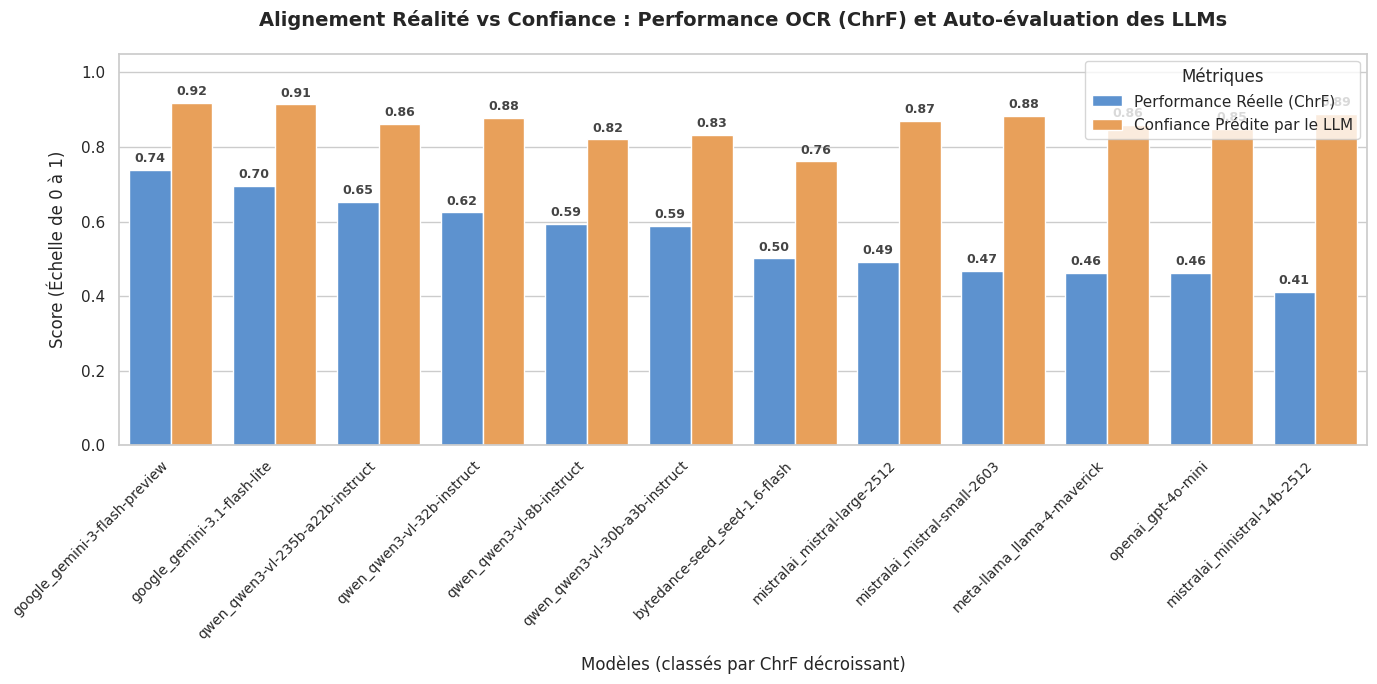

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

df_plot = df_results.groupby('model')[['chrf_score', 'confidence_reported']].mean().reset_index()

df_melted = df_plot.melt(
    id_vars='model',
    value_vars=['chrf_score', 'confidence_reported'],
    var_name='Type de Métrique',
    value_name='Valeur'
)

# Rendre les étiquettes de la légende plus élégantes
df_melted['Type de Métrique'] = df_melted['Type de Métrique'].replace({
    'chrf_score': 'Performance Réelle (ChrF)',
    'confidence_reported': 'Confiance Prédite par le LLM'
})

plt.figure(figsize=(14, 7))
sns.set_theme(style="whitegrid")

model_order = df_plot.sort_values(by='chrf_score', ascending=False)['model']

ax = sns.barplot(
    x='model',
    y='Valeur',
    hue='Type de Métrique',
    data=df_melted,
    order=model_order,
    palette=['#4A90E2', '#FF9F43'] 
)

plt.title(
    "Alignement Réalité vs Confiance : Performance OCR (ChrF) et Auto-évaluation des LLMs",
    fontsize=14,
    fontweight='bold',
    pad=20
)
plt.xlabel("Modèles (classés par ChrF décroissant)", fontsize=12, labelpad=10)
plt.ylabel("Score (Échelle de 0 à 1)", fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.ylim(0, 1.05) 
plt.legend(title="Métriques", loc='upper right', frameon=True)

for p in ax.patches:
    height = p.get_height()
    if height > 0: # Évite d'annoter les barres vides ou buggées
        ax.annotate(
            f'{height:.2f}',
            (p.get_x() + p.get_width() / 2., height),
            ha='center',
            va='center',
            xytext=(0, 8),
            textcoords='offset points',
            fontsize=9,
            fontweight='semibold',
            color='#444444'
        )

plt.tight_layout()
plt.show()

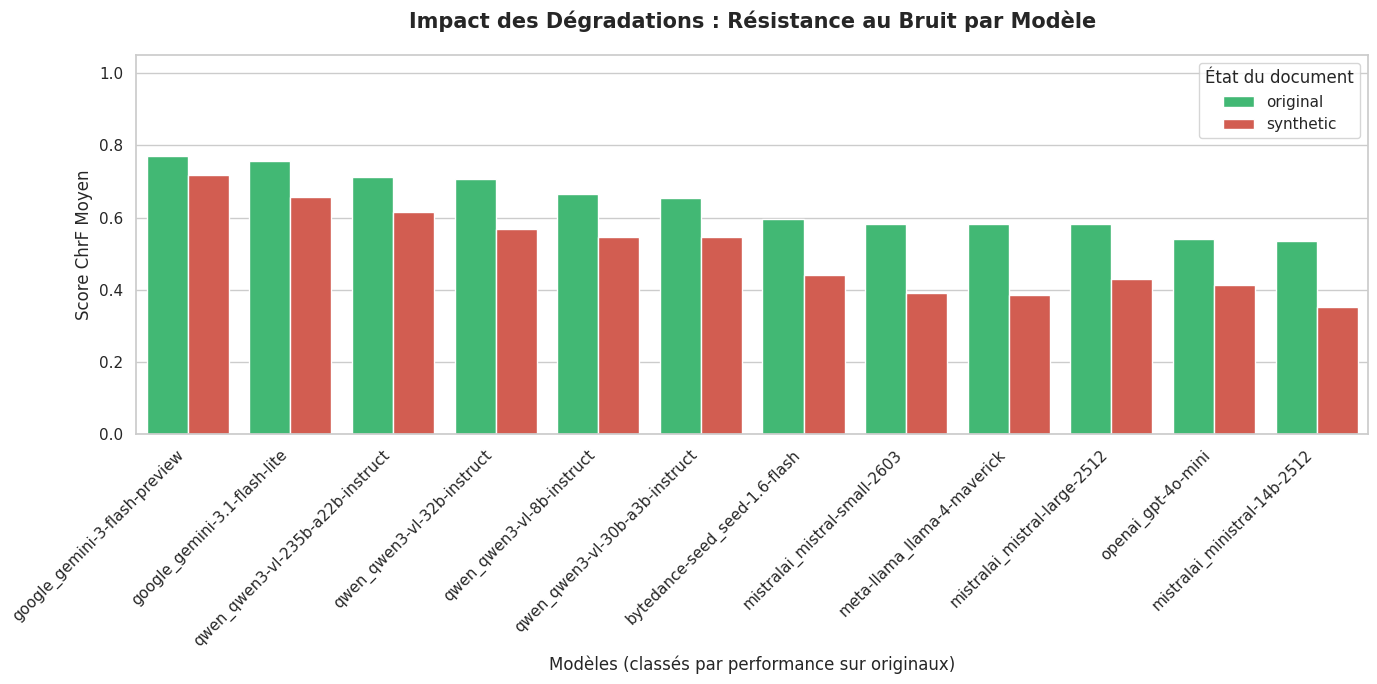

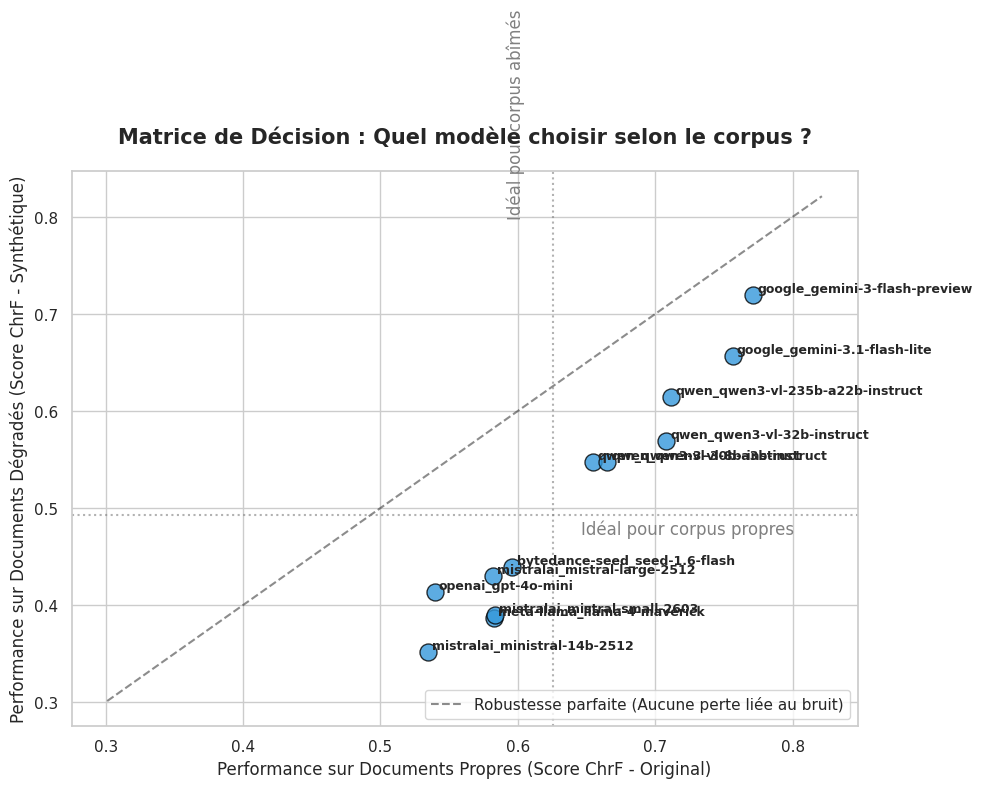

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configuration générale du style visuel
sns.set_theme(style="whitegrid")

df_deg = df_results.groupby(['model', 'img_type'])['chrf_score'].mean().reset_index()

order_models = df_deg[df_deg['img_type'] == 'original'].sort_values('chrf_score', ascending=False)['model']

plt.figure(figsize=(14, 7))
ax1 = sns.barplot(
    data=df_deg,
    x='model',
    y='chrf_score',
    hue='img_type',
    order=order_models,
    palette=['#2ecc71', '#e74c3c'] 
)

plt.title("Impact des Dégradations : Résistance au Bruit par Modèle", fontsize=15, fontweight='bold', pad=20)
plt.xlabel("Modèles (classés par performance sur originaux)", fontsize=12)
plt.ylabel("Score ChrF Moyen", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 1.05)
plt.legend(title="État du document", loc='upper right')

plt.tight_layout()
plt.show()

df_decision = df_results.groupby(['model', 'img_type'])['chrf_score'].mean().unstack().reset_index()

# On retire les modèles qui n'auraient pas été évalués sur les deux types pour éviter les erreurs
df_decision = df_decision.dropna()

plt.figure(figsize=(10, 8))

sns.scatterplot(
    data=df_decision,
    x='original',
    y='synthetic',
    s=150, 
    color='#3498db',
    edgecolor='black',
    alpha=0.8
)

min_val = min(df_decision['original'].min(), df_decision['synthetic'].min()) - 0.05
max_val = max(df_decision['original'].max(), df_decision['synthetic'].max()) + 0.05
plt.plot([min_val, max_val], [min_val, max_val], 'k--', alpha=0.5, label="Robustesse parfaite (Aucune perte liée au bruit)")

median_orig = df_decision['original'].median()
median_synth = df_decision['synthetic'].median()
plt.axvline(median_orig, color='gray', linestyle=':', alpha=0.6)
plt.axhline(median_synth, color='gray', linestyle=':', alpha=0.6)

for i in range(df_decision.shape[0]):
    plt.text(
        df_decision['original'].iloc[i] + 0.003,
        df_decision['synthetic'].iloc[i] + 0.003,
        df_decision['model'].iloc[i],
        fontsize=9,
        weight='semibold'
    )

plt.title("Matrice de Décision : Quel modèle choisir selon le corpus ?", fontsize=15, fontweight='bold', pad=20)
plt.xlabel("Performance sur Documents Propres (Score ChrF - Original)", fontsize=12)
plt.ylabel("Performance sur Documents Dégradés (Score ChrF - Synthétique)", fontsize=12)
plt.legend(loc='lower right')

plt.text(max_val - 0.02, median_synth - 0.02, "Idéal pour corpus propres", color='gray', ha='right')
plt.text(median_orig - 0.02, max_val - 0.02, "Idéal pour corpus abîmés", color='gray', ha='right', rotation=90)

plt.tight_layout()
plt.show()

In [ ]:
import os
import re
import json
import pandas as pd
import difflib
import warnings
from nltk.translate.chrf_score import sentence_chrf
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction

warnings.filterwarnings('ignore')

RESULTS_DIR = os.path.join(BASE_PATH, "benchmark_results")
RAW_TXT_DIR = os.path.join(BASE_PATH, "raw_txt")

def clean_latex_for_evaluation(text):
    if not text: return ""
    text = re.sub(r'\s+', ' ', text)
    text = re.sub(r'\s*([+\-*/=<>_^(),\\{}])\s*', r'\1', text)
    text = text.replace(r'\[', '$$').replace(r'\]', '$$').replace(r'\(', '$').replace(r'\)', '$')
    synonyms = {r'\leq': r'\le', r'\geq': r'\ge', r'\rightarrow': r'\to', r'\text': r'\mathrm'}
    for old, new in synonyms.items():
        text = text.replace(old, new)
    return text.strip()

def evaluate_all_metrics(test_limit=None):
    all_results = []
    json_files = [f for f in os.listdir(RESULTS_DIR) if f.endswith('.json')]

    if test_limit:
        json_files = json_files[:test_limit]
        print(f"MODE TEST : {len(json_files)} fichiers.")

    for j_file in json_files:
        parts = j_file.replace(".json", "").split("__")
        if len(parts) != 3: continue

        safe_model_name, img_name, prompt_id = parts
        img_type = "synthetic" if "synthetic" in img_name.lower() else "original"

        base_img_name = re.sub(r'_synthetic_\d+', '', img_name)
        core_name = os.path.splitext(base_img_name)[0]
        gt_path = os.path.join(RAW_TXT_DIR, f"{core_name}.txt")

        if not os.path.exists(gt_path): continue

        with open(gt_path, 'r', encoding='utf-8') as f:
            ground_truth = f.read().strip()

        pred_path = os.path.join(RESULTS_DIR, j_file)
        try:
            with open(pred_path, 'r', encoding='utf-8') as f:
                pred_data = json.load(f)
                model_response = pred_data.get("model_response", {})
                prediction = model_response.get("transcription", "").strip()
                confidence_score = model_response.get("confidence_score", None)
        except Exception:
            continue

        gt_clean = clean_latex_for_evaluation(ground_truth)
        pred_clean = clean_latex_for_evaluation(prediction)


        # 1. ChrF
        chrf = sentence_chrf(gt_clean, pred_clean) if pred_clean else 0.0

        # 2. CER Similarity (Distance de Levenshtein textuelle normalisée)
        cer_sim = difflib.SequenceMatcher(None, gt_clean, pred_clean).ratio()

        # 3. BLEU Score (Lissé pour les courtes équations)
        gt_tokens = gt_clean.split()
        pred_tokens = pred_clean.split()
        smooth = SmoothingFunction().method1
        # Poids (0.5, 0.5) pour se concentrer sur les unigrammes et bigrammes
        bleu = sentence_bleu([gt_tokens], pred_tokens, weights=(0.5, 0.5, 0, 0), smoothing_function=smooth) if pred_tokens else 0.0

        # 4. Jaccard Similarity (Tokens en commun vs Total des tokens)
        set_gt = set(gt_tokens)
        set_pred = set(pred_tokens)
        intersection = len(set_gt.intersection(set_pred))
        union = len(set_gt.union(set_pred))
        jaccard = intersection / union if union > 0 else 0.0

        all_results.append({
            "model": safe_model_name,
            "img_type": img_type,
            "prompt_id": prompt_id,
            "confidence_reported": confidence_score,
            "chrf_score": chrf,
            "cer_similarity": cer_sim,
            "bleu_score": bleu,
            "jaccard_score": jaccard
        })

    return pd.DataFrame(all_results)

df_multi_metrics = evaluate_all_metrics(test_limit=None)
print(f"Évaluation terminée sur {len(df_multi_metrics)} prédictions.")

Évaluation terminée sur 3214 prédictions.



📊 ANALYSE SELON LA MÉTRIQUE : ChrF Score (Équilibre)



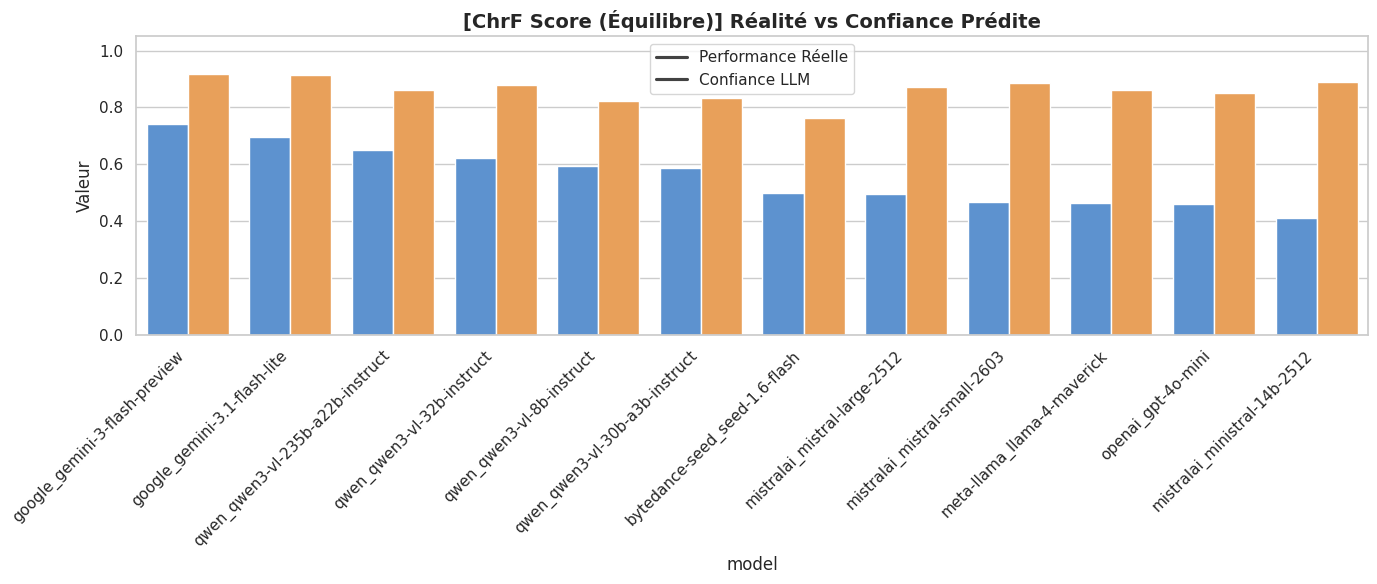

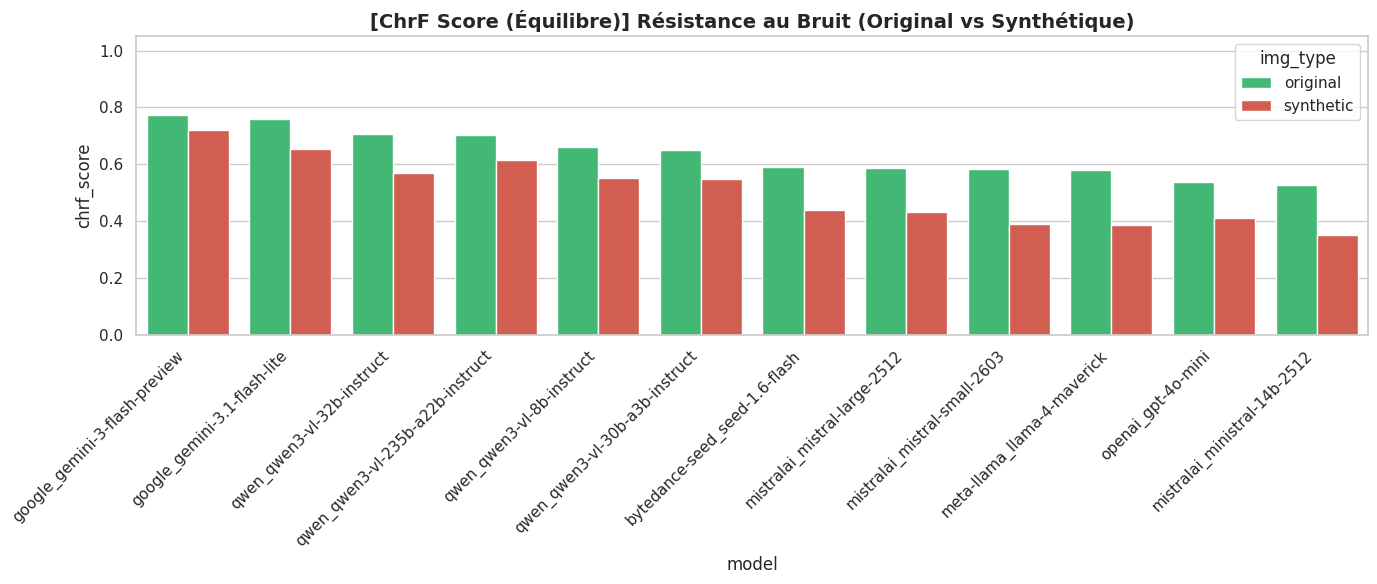

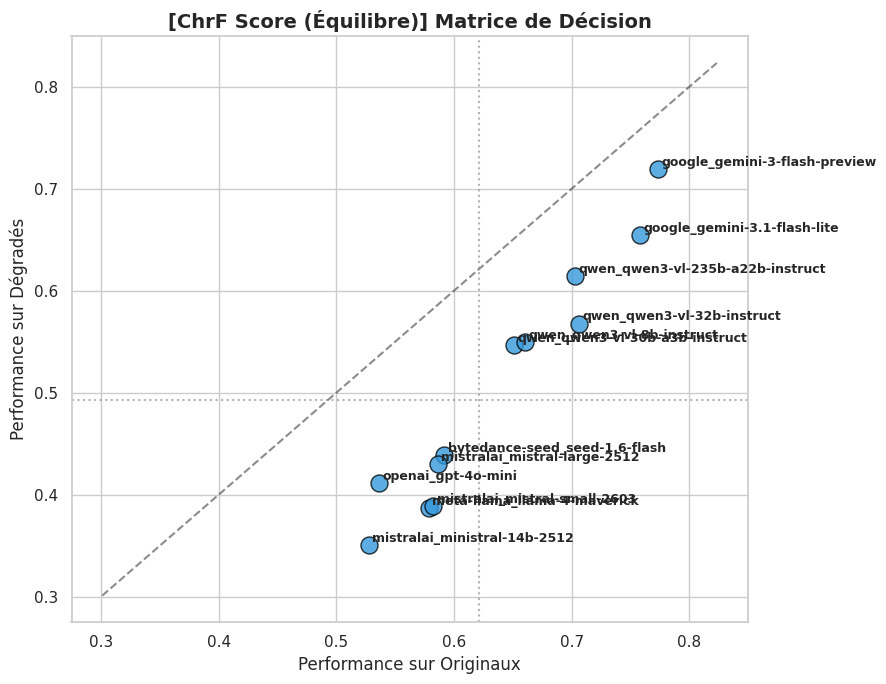


📊 ANALYSE SELON LA MÉTRIQUE : CER Similarity (Rigueur)



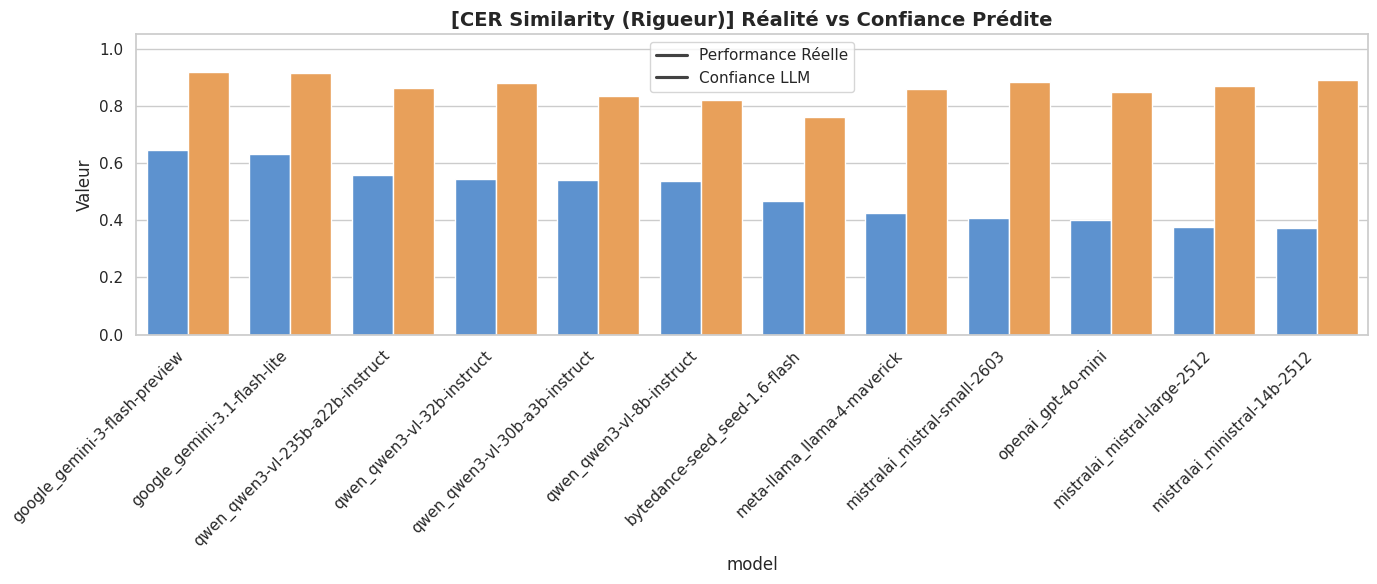

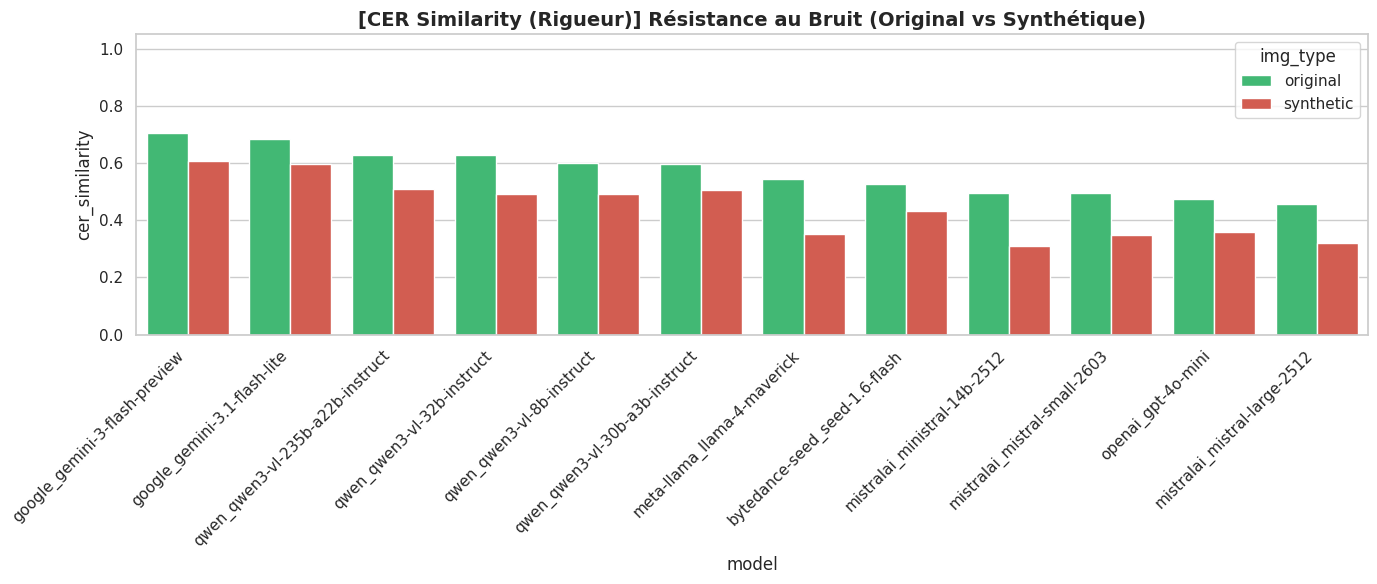

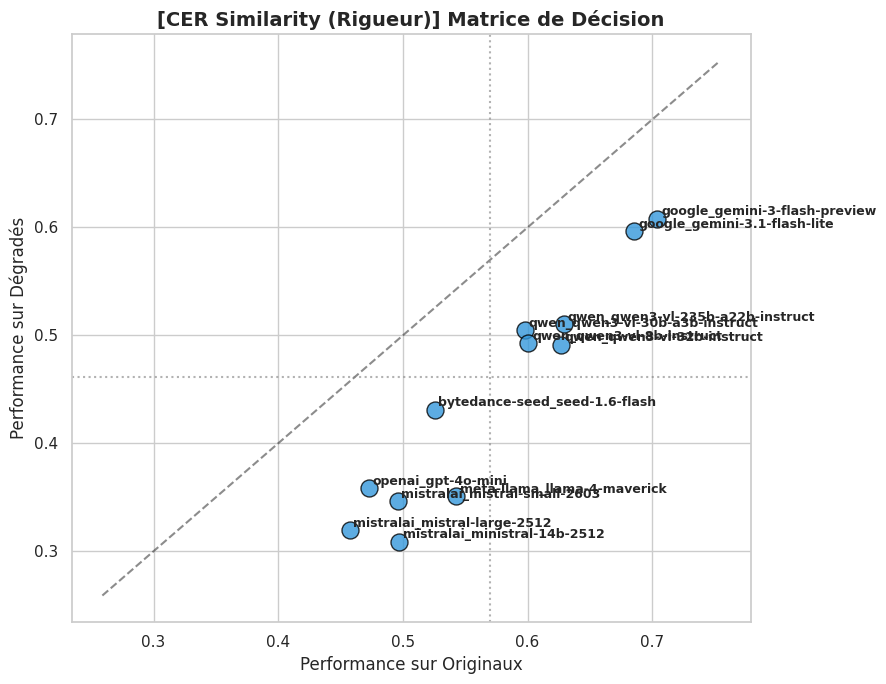


📊 ANALYSE SELON LA MÉTRIQUE : BLEU Score (Précision Commandes)



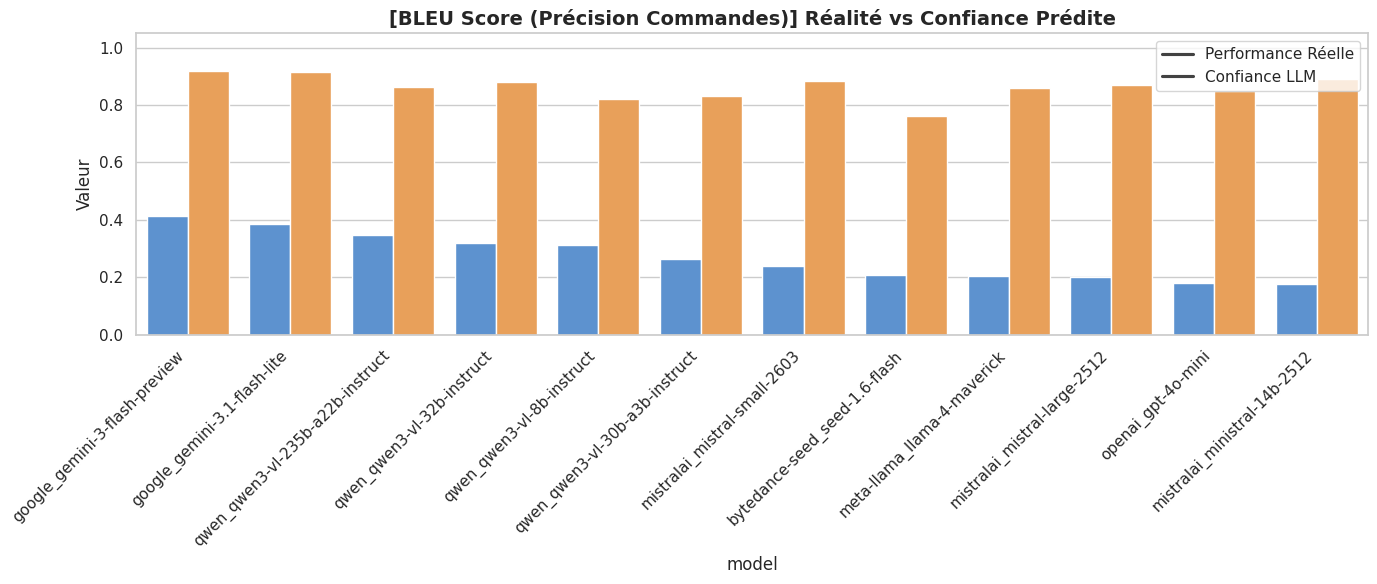

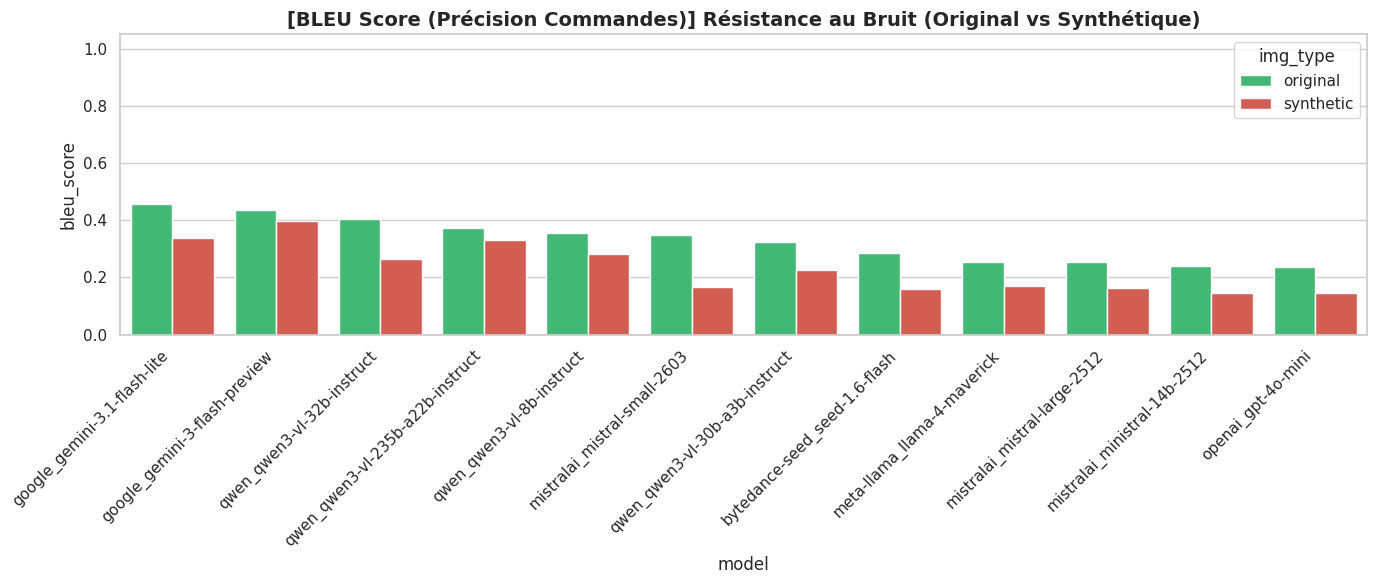

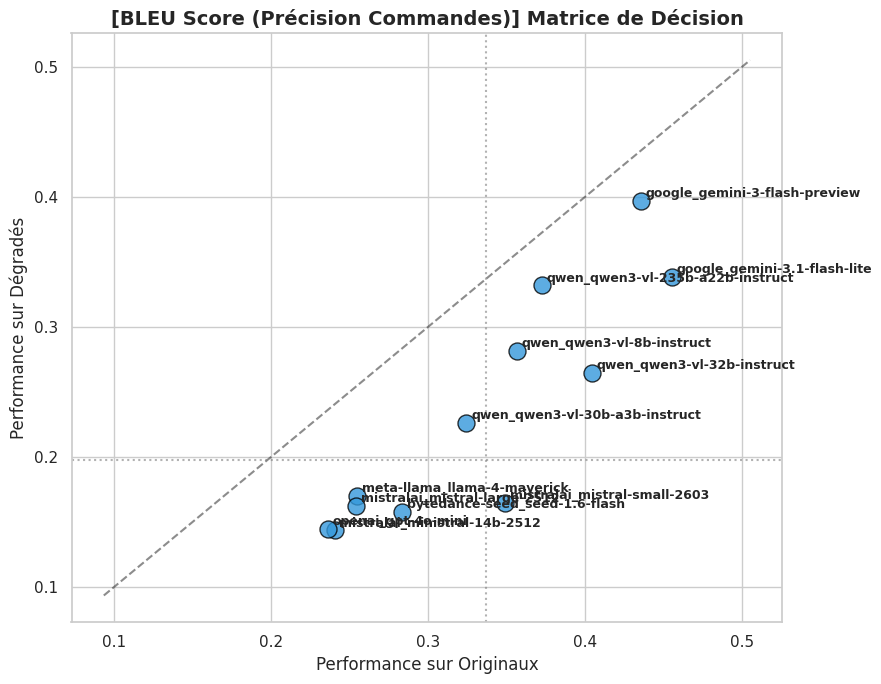


📊 ANALYSE SELON LA MÉTRIQUE : Jaccard Score (Présence Sémantique)



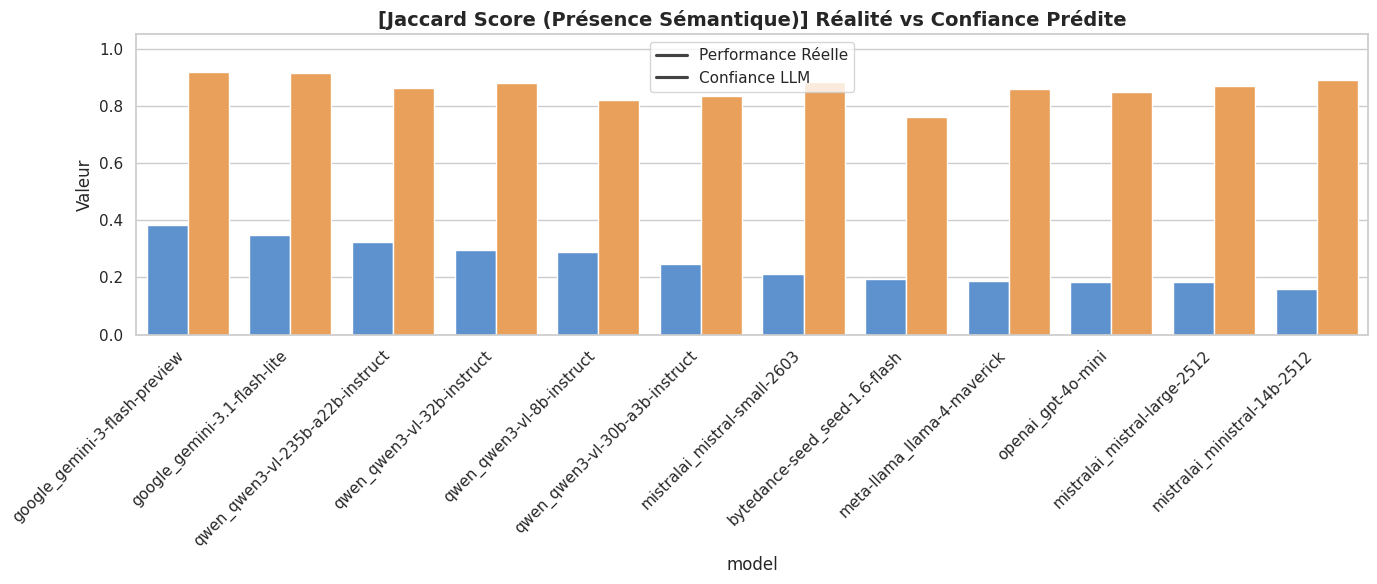

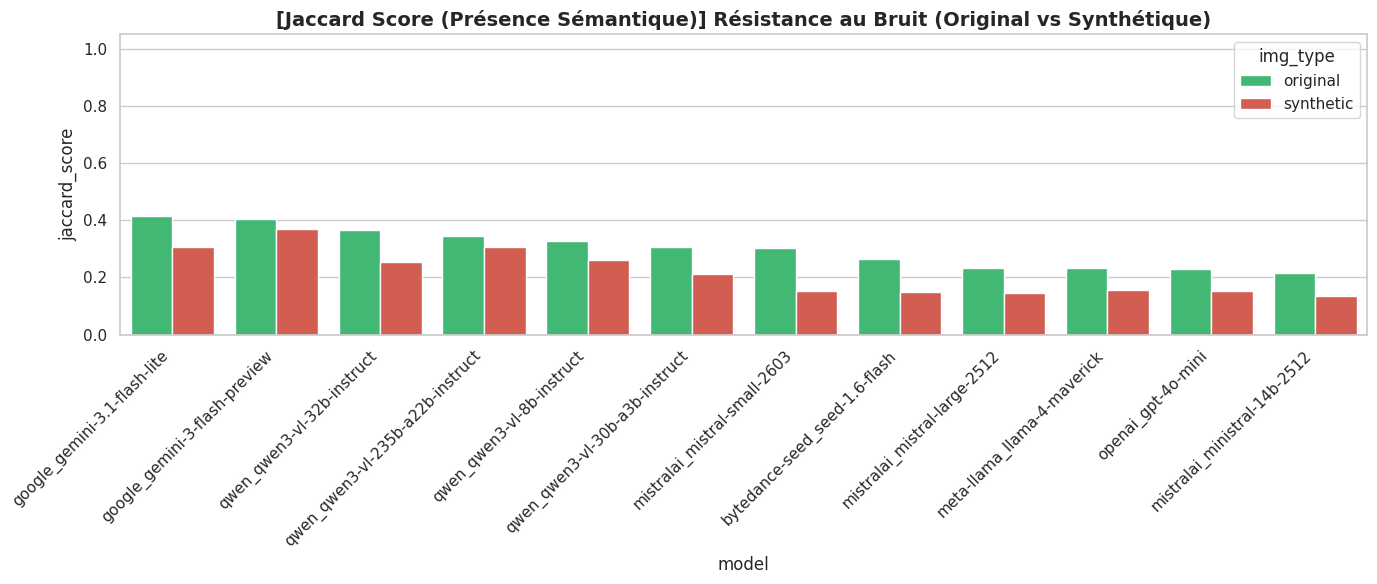

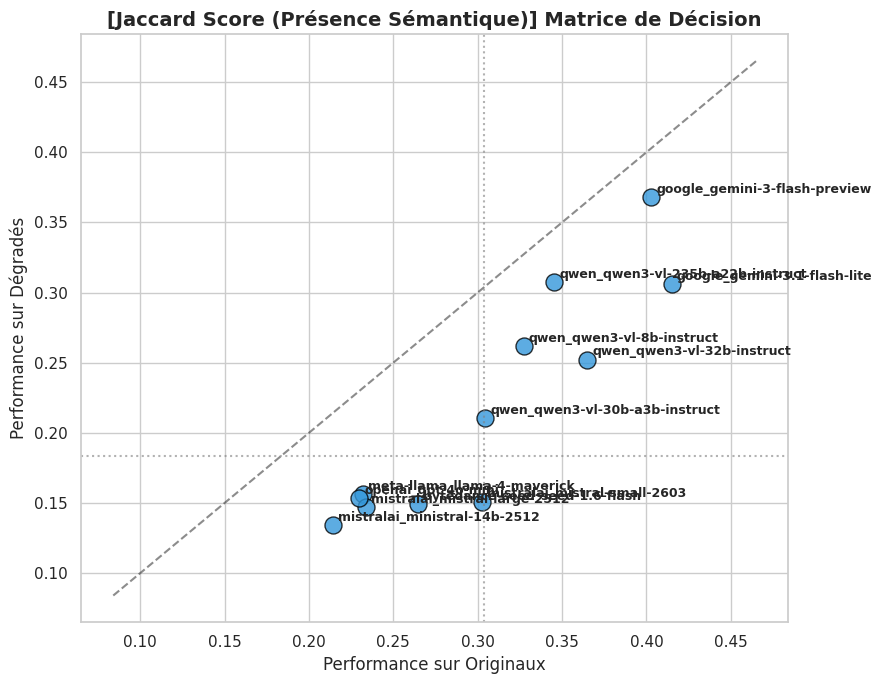

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

metrics_dict = {
    'chrf_score': 'ChrF Score (Équilibre)',
    'cer_similarity': 'CER Similarity (Rigueur)',
    'bleu_score': 'BLEU Score (Précision Commandes)',
    'jaccard_score': 'Jaccard Score (Présence Sémantique)'
}

def generate_plots_for_metric(df, metric_col, metric_name):
    print(f"\n{'='*50}\n📊 ANALYSE SELON LA MÉTRIQUE : {metric_name}\n{'='*50}\n")
    # encore une fois, ces smileys sont vraiment hideux

    df_plot1 = df.groupby('model')[[metric_col, 'confidence_reported']].mean().reset_index()
    df_melted = df_plot1.melt(id_vars='model', value_vars=[metric_col, 'confidence_reported'],
                              var_name='Type', value_name='Valeur')

    plt.figure(figsize=(14, 6))
    order_models = df_plot1.sort_values(by=metric_col, ascending=False)['model']
    ax = sns.barplot(x='model', y='Valeur', hue='Type', data=df_melted, order=order_models, palette=['#4A90E2', '#FF9F43'])
    plt.title(f"[{metric_name}] Réalité vs Confiance Prédite", fontsize=14, fontweight='bold')
    plt.xticks(rotation=45, ha='right')
    plt.ylim(0, 1.05)
    plt.legend(['Performance Réelle', 'Confiance LLM'])
    plt.tight_layout()
    plt.show()

    df_deg = df.groupby(['model', 'img_type'])[metric_col].mean().reset_index()
    order_models_deg = df_deg[df_deg['img_type'] == 'original'].sort_values(metric_col, ascending=False)['model']

    plt.figure(figsize=(14, 6))
    sns.barplot(data=df_deg, x='model', y=metric_col, hue='img_type', order=order_models_deg, palette=['#2ecc71', '#e74c3c'])
    plt.title(f"[{metric_name}] Résistance au Bruit (Original vs Synthétique)", fontsize=14, fontweight='bold')
    plt.xticks(rotation=45, ha='right')
    plt.ylim(0, 1.05)
    plt.tight_layout()
    plt.show()

    df_decision = df.groupby(['model', 'img_type'])[metric_col].mean().unstack().dropna().reset_index()

    plt.figure(figsize=(9, 7))
    sns.scatterplot(data=df_decision, x='original', y='synthetic', s=150, color='#3498db', edgecolor='black', alpha=0.8)

    min_val = min(df_decision['original'].min(), df_decision['synthetic'].min()) - 0.05
    max_val = max(df_decision['original'].max(), df_decision['synthetic'].max()) + 0.05
    plt.plot([min_val, max_val], [min_val, max_val], 'k--', alpha=0.5)

    plt.axvline(df_decision['original'].median(), color='gray', linestyle=':', alpha=0.6)
    plt.axhline(df_decision['synthetic'].median(), color='gray', linestyle=':', alpha=0.6)

    for i in range(df_decision.shape[0]):
        plt.text(df_decision['original'].iloc[i] + 0.003, df_decision['synthetic'].iloc[i] + 0.003,
                 df_decision['model'].iloc[i], fontsize=9, weight='semibold')

    plt.title(f"[{metric_name}] Matrice de Décision", fontsize=14, fontweight='bold')
    plt.xlabel("Performance sur Originaux")
    plt.ylabel("Performance sur Dégradés")
    plt.tight_layout()
    plt.show()

for col, name in metrics_dict.items():
    generate_plots_for_metric(df_multi_metrics, col, name)

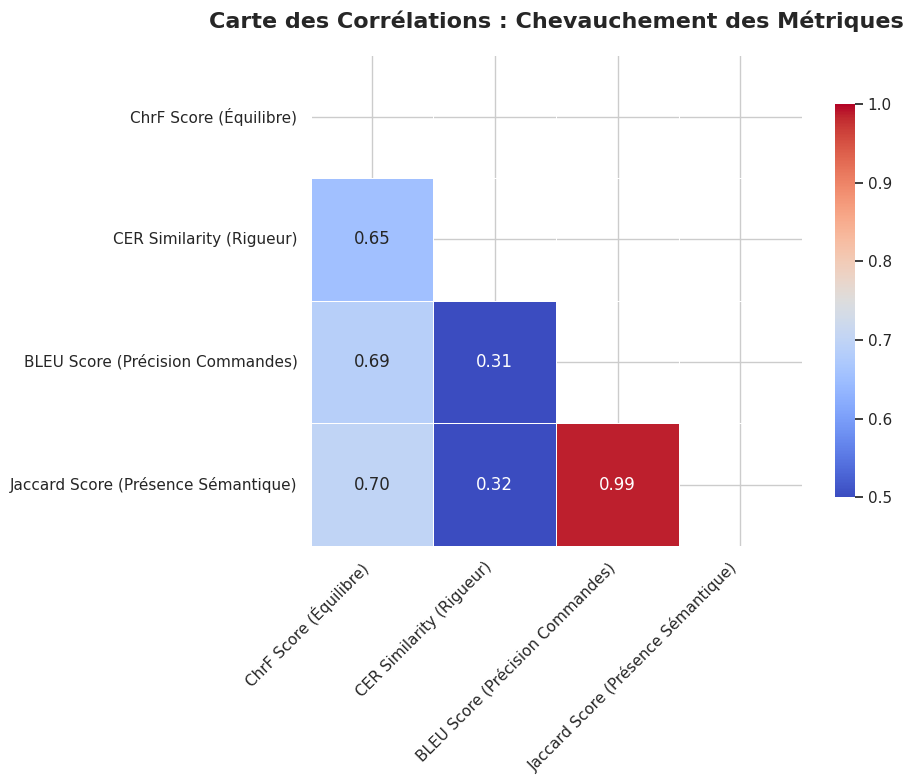

In [ ]:

plt.figure(figsize=(10, 8))

df_metrics_only = df_multi_metrics[['chrf_score', 'cer_similarity', 'bleu_score', 'jaccard_score']].dropna()
correlation_matrix = df_metrics_only.corr()

renamed_matrix = correlation_matrix.rename(
    index=metrics_dict,
    columns=metrics_dict
)

# Génération de la Heatmap
mask = np.triu(np.ones_like(renamed_matrix, dtype=bool))
sns.heatmap(renamed_matrix, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=0.5, vmax=1.0, square=True, linewidths=.5, cbar_kws={"shrink": .8})

plt.title("Carte des Corrélations : Chevauchement des Métriques", fontsize=16, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()
# ULTRA BIZARRE, NON.